# Modelling

Goal: predict whether a session ends in a purchase (`Revenue`).
Findings from `01_data_exploration.ipynb` guide the choices here.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../Data/online_shoppers_intention.csv")

## 1. Train/test split

In [2]:
X = df.drop(columns="Revenue")
y= df["Revenue"]

X.shape, y.shape

((12330, 17), (12330,))

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, 
stratify=y, 
random_state=42,)

print(f"Train: {len(X_train)} rows, purchase rate {y_train.mean():.1%}")
print(f"Test:  {len(X_test)} rows, purchase rate {y_test.mean():.1%}")

Train: 9864 rows, purchase rate 15.5%
Test:  2466 rows, purchase rate 15.5%


In [4]:
X_train.shape

(9864, 17)

## 2. Preparing the features

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
numeric_cols = [col for col in X_train.columns if col not in categorical_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_train_prepared.shape

(9864, 74)

## 3. Baseline model: Logistic regression

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

log_reg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

log_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Administrative','Administrative_Duration','Informational',..., 'TrafficType','VisitorType','Weekend']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By speci

In [7]:
accuracy = log_reg.score(X_test, y_test)
print(f"Test accuary: {accuracy:.1%}")

Test accuary: 88.1%


## 4. Evaluating the baseline

In [8]:
from sklearn.metrics import classification_report

y_pred = log_reg.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.89      0.98      0.93      2084
        True       0.74      0.36      0.48       382

    accuracy                           0.88      2466
   macro avg       0.81      0.67      0.71      2466
weighted avg       0.87      0.88      0.86      2466



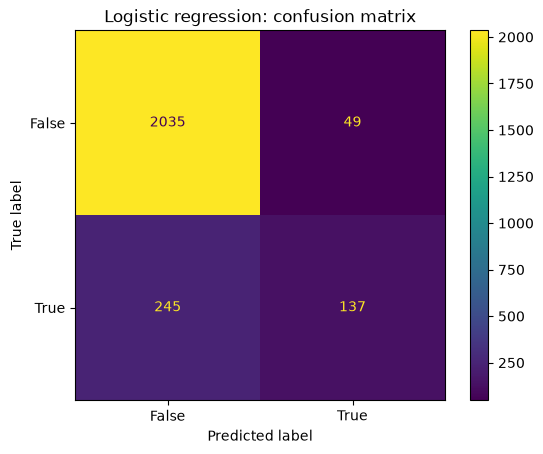

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Logistic regression: confusion matrix")
plt.show()

## 5. Handling class imbalance

In [10]:
log_reg_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

log_reg_balanced.fit(X_train, y_train)
y_pred_balanced = log_reg_balanced.predict(X_test)

print(f"Test accuracy: {log_reg_balanced.score(X_test, y_test):.1%}")
print(classification_report(y_test, y_pred_balanced))

Test accuracy: 84.1%
              precision    recall  f1-score   support

       False       0.95      0.86      0.90      2084
        True       0.49      0.74      0.59       382

    accuracy                           0.84      2466
   macro avg       0.72      0.80      0.75      2466
weighted avg       0.88      0.84      0.85      2466



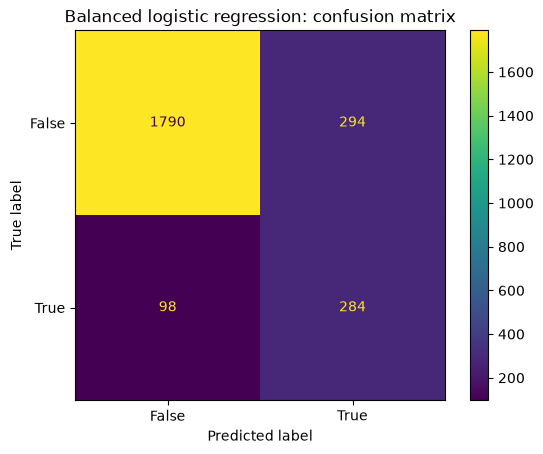

In [11]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_balanced)
plt.title("Balanced logistic regression: confusion matrix")
plt.show()

### Findings

- Baseline logistic regression: accuracy **88.1%**, precision **74%**, recall **36%**. It found **137 of 382** buyers, with **48** false alarms.
- With `class_weight="balanced"`: accuracy **84.1%**, precision **49%**, recall **74%**. It found **284 of 382** buyers, but false alarms rose to **294**.
- F1-score for buyers improved from **0.48** to **0.59**.

**So what:**
- Accuracy dropped below the 84.5% baseline, yet the balanced model is far more useful, because it finds twice as many buyers. Accuracy is the wrong way to judge this problem.
- There is a trade-off: higher recall means more false alarms. For showing a discount, a false alarm is cheap, so the **balanced model is the better choice**.
- Next, try a model that can learn more complex patterns (random forest) to see whether precision and recall can both improve.

## 6. Random forest

In [12]:
from sklearn.ensemble import RandomForestClassifier

forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=1,)),
])

forest.fit(X_train, y_train)
y_pred_forest = forest.predict(X_test)

print(f"Test accuracy: {forest.score(X_test, y_test):.1%}")
print(classification_report(y_test, y_pred_forest))

Test accuracy: 89.0%
              precision    recall  f1-score   support

       False       0.94      0.93      0.93      2084
        True       0.63      0.70      0.66       382

    accuracy                           0.89      2466
   macro avg       0.79      0.81      0.80      2466
weighted avg       0.90      0.89      0.89      2466



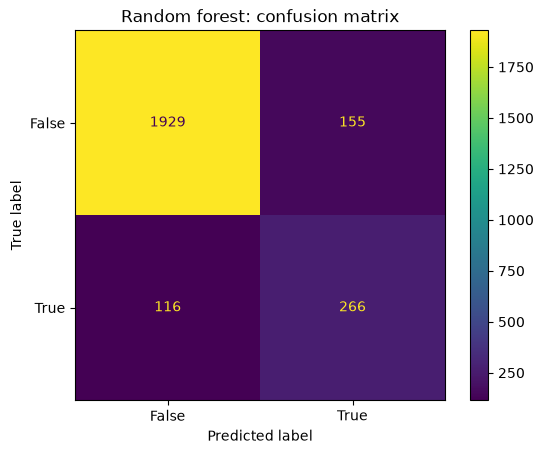

In [13]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_forest)
plt.title("Random forest: confusion matrix")
plt.show()

## 7. How much does the model depends on PageValues?

In [15]:
X_train_no_pv = X_train.drop(columns="PageValues")
X_test_no_pv = X_test.drop(columns="PageValues")

numeric_cols_no_pv = [col for col in numeric_cols if col != "PageValues"]

preprocessor_no_pv = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols_no_pv),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

forest_no_pv = Pipeline([
    ("preprocessor", preprocessor_no_pv),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

forest_no_pv.fit(X_train_no_pv, y_train)
y_pred_no_pv = forest_no_pv.predict(X_test_no_pv)

print(f"Test accuracy: {forest_no_pv.score(X_test_no_pv, y_test):.1%}")
print(classification_report(y_test, y_pred_no_pv))

Test accuracy: 82.4%
              precision    recall  f1-score   support

       False       0.88      0.92      0.90      2084
        True       0.41      0.31      0.35       382

    accuracy                           0.82      2466
   macro avg       0.64      0.61      0.62      2466
weighted avg       0.81      0.82      0.81      2466



### Findings

| Model | Accuracy | Precision | Recall | F1 | Found (of 382) | False alarms |
|---|---|---|---|---|---|---|
| Logistic regression | 88.1% | 74% | 36% | 0.48 | 137 | 48 |
| Logistic regression (balanced) | 84.1% | 49% | 74% | 0.59 | 284 | 294 |
| Random forest (balanced) | 89.4% | 63% | 70% | 0.66 | 266 | 155 |
| Random forest, no PageValues | 82.4% | 41% | 31% | 0.35 | 118 | 171 |

**So what:**
- The **balanced random forest is the best model**: the highest F1, and far fewer false alarms than balanced logistic regression, while finding almost as many buyers.
- The model **depends heavily on PageValues**. Without it, F1 almost halves (0.66 → 0.35) and accuracy falls below the 84.5% baseline.
- PageValues may not be available early in a session, so the model works best for predicting purchases later in a session, after several pages have been viewed.